# Radiative forcing decomposition (design A)

Six-map figures: what the forest expansion does to the TOA radiation, split into the **land-cover total** and its **BVOC part** (user 2026-11-16; before in `artefact-corrected-split.ipynb` §3, and up to 2026-11-08 in `radiative_forcing.ipynb` §1b).

| Maps | Contrast | Category |
|---|---|---|
| 1 albedo / SW clear-sky proxy, 2 total | `[LCC − CTRL] _P` = LCC_P − CTRL_P; FUT with PD emissions (user 2026-11-19): E = lccPD → LCC_FUT − LCC_PD, E = ctrlPD → LCC_FUT − CTRL_PD | interactive |
| 3–6 BVOC-related, SOA-cloud, direct SOA, chemistry/residual | `LCC_P_fBVOC [lccP − E]` = LCC_P_fBVOClccP − LCC_P_fBVOC*E* | fBVOC (design A: both runs prescribed, no artefact) |

Maps 3–6 are computed as LCC_P − V with the virtual run V = LCC_P − LCC_P_fBVOClccP + LCC_P_fBVOC*E* (`VirtualRun`), which gives exactly LCC_P_fBVOClccP − LCC_P_fBVOC*E*.

**Design A split** (§2): [LCC − CTRL]_P = non-BVOC + BVOC_A + δ, with non-BVOC = [LCC_P − CTRL_P]_fBVOCctrlP, BVOC_A = LCC_P_fBVOC [lccP − ctrlP], δ_P = art_LCC_P − art_CTRL_P (artefacts, in `results/figures/artefacts/d_artefacts/`). Design B is in `artefact-corrected-split.ipynb` → `results/figures/artefacts/design-B/`.

**Names** (aliases of `results/pptx/simulations-interpretation.pptx`). **Colour scales** (user 2026-11-16, from the 98th percentile of |map| ≥ 45°N): same period (E = ctrlP) `split6-0.5`; FUT with PD emissions and LCC_FUT − CTRL_PD `split40-15-2` (before 2026-11-19 the FUT-with-PD-emission figures showed [LCC − CTRL]_FUT on `split6-2`) (albedo ±40, total ±15, BVOC ±2); only these shared-scale versions are drawn (user 2026-11-20: per-map-colourbar versions dropped, as was the duplicate case LCCFUT-CTRLPD_fBVOCctrlPD = LCCFUT_fBVOCctrlPD). **Files** `<LCCP>_fBVOC<E>_forcing_decomposition_<band>_<y0>_<y1>[_<scale>]_designA.png` in `results/figures/radiative-forcing-decomposition/` (they mix categories, so no a_/b_/c_ subfolder).

**Caveats.** Mean over the 25 nudged years 2001–2025 (first 12 months dropped); numbers under the maps = area-weighted mean ≥ 45°N ± 95 % t-interval of the yearly means; hatching = not significant (FDR). The albedo proxy is a clear-sky SW quantity, shown for orientation.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display
from boreal_forest_expansion.plotting.style import set_default_style
from boreal_forest_expansion.plotting import forcing_maps as fm

set_default_style()
pd.set_option("display.width", 220, "display.max_rows", 200)
START_YEAR, END_YEAR = 2001, 2025
FIG, TAB = fm.set_output_notebook("radiative-forcing-decomposition")
common = dict(start_year=START_YEAR, end_year=END_YEAR, extent_lat=45, mean_lat_min=45, save=True, figdir=FIG,
              transparent_background=True)


def bvoc_ref(P, E):
    """V with LCC_P − V = LCC_P_fBVOClccP − LCC_P_fBVOC<E> (design A)."""
    return fm.VirtualRun(f"LCC_{P}_fBVOC{E}_A", {f"LCC_{P}": 1.0, f"LCC_{P}_fBVOClcc{P}": -1.0, f"LCC_{P}_fBVOC{E}": 1.0})


# tag -> (pairs, total label, BVOC label, family scales)
CASES = {}
# maps 1–2 (case2 = "ctrl" role): [LCC − CTRL]_P; FUT with PD emissions E: LCC_FUT − <E's run> (user 2026-11-19),
# i.e. E = lccPD → LCC_FUT − LCC_PD, E = ctrlPD → LCC_FUT − CTRL_PD (98th pct |map| ≥ 45°N: albedo 38, total 12–20)
for P, E, ref, scale in (("PD", "ctrlPD", "CTRL_PD", "split6-0.5"), ("FUT", "ctrlFUT", "CTRL_FUT", "split6-0.5"),
                         ("FUT", "lccPD", "LCC_PD", "split40-15-2"), ("FUT", "ctrlPD", "CTRL_PD", "split40-15-2")):
    tot = f"[LCC − CTRL] _{P}" if ref == f"CTRL_{P}" else f"LCC_{P} − {ref}"
    CASES[f"LCC{P}_fBVOC{E}"] = ({"lcc": f"LCC_{P}", "ctrl": ref, "fbvoc": bvoc_ref(P, E)},
                                 tot, f"LCC_{P}_fBVOC [lcc{P} − {E}]", scale)
# LCC and climate change together (user 2026-11-16) = the FUT, E = ctrlPD case above (own tag dropped 2026-11-20)
for tag, (pairs, tot, bvoc, scale) in CASES.items():
    print(f"{tag:28s} {tot:20s} | {bvoc:34s} | {scale:13s} V = {pairs['fbvoc'].weights}")
    for a in {pairs["lcc"], pairs["ctrl"], *pairs["fbvoc"].weights}:
        assert fm.filename(a, "RADIATIVE", START_YEAR, END_YEAR, "atm").exists(), a
print("inputs present ✓")

LCCPD_fBVOCctrlPD            [LCC − CTRL] _PD     | LCC_PD_fBVOC [lccPD − ctrlPD]      | split6-0.5    V = {'LCC_PD': 1.0, 'LCC_PD_fBVOClccPD': -1.0, 'LCC_PD_fBVOCctrlPD': 1.0}
LCCFUT_fBVOCctrlFUT          [LCC − CTRL] _FUT    | LCC_FUT_fBVOC [lccFUT − ctrlFUT]   | split6-0.5    V = {'LCC_FUT': 1.0, 'LCC_FUT_fBVOClccFUT': -1.0, 'LCC_FUT_fBVOCctrlFUT': 1.0}
LCCFUT_fBVOClccPD            LCC_FUT − LCC_PD     | LCC_FUT_fBVOC [lccFUT − lccPD]     | split40-15-2  V = {'LCC_FUT': 1.0, 'LCC_FUT_fBVOClccFUT': -1.0, 'LCC_FUT_fBVOClccPD': 1.0}
LCCFUT_fBVOCctrlPD           LCC_FUT − CTRL_PD    | LCC_FUT_fBVOC [lccFUT − ctrlPD]    | split40-15-2  V = {'LCC_FUT': 1.0, 'LCC_FUT_fBVOClccFUT': -1.0, 'LCC_FUT_fBVOCctrlPD': 1.0}
LCCFUT-CTRLPD_fBVOCctrlPD    LCC_FUT − CTRL_PD    | LCC_FUT_fBVOC [lccFUT − ctrlPD]    | split40-15-2  V = {'LCC_FUT': 1.0, 'LCC_FUT_fBVOClccFUT': -1.0, 'LCC_FUT_fBVOCctrlPD': 1.0}
inputs present ✓


## 1. Six-map forcing decomposition
One figure per case and band (NET, SW, LW), with the family colour scale (shared per family).

RuntimeError: NetCDF: HDF error

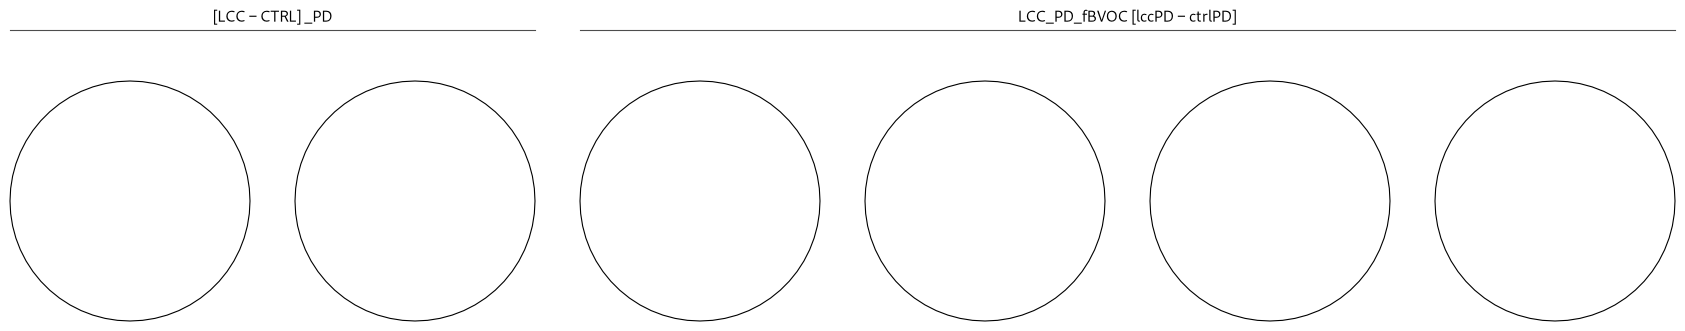

In [2]:
for tag, (pairs, tot, bvoc, scale) in CASES.items():
    for band in ("NET", "SW", "LW"):
        fig, axes = fm.make_forcing_summary_figure(tag, band=band, pairs=pairs, scales=scale, design="designA",
                                                   title=tot, group_labels={"ctrl": tot, "fbvoc": bvoc}, **common)
        plt.show(); plt.close(fig)

## 2. Design A split of the NET budget
Total [LCC − CTRL]_P = non-BVOC + BVOC_A + δ_P, checked year by year **before** averaging; FUT also BVOC_A with E = lccPD, ctrlPD (not part of the closed split). Regions: global, ≥ 45°N, modified cells. Bars = Ghan terms, mean ± 95 % CI over the 25 yearly means.

In [3]:
REGIONS = ("global", "≥45°N", "modified cells")

def masks_for(ds):
    m = fm.region_masks(ds)
    m["global"] = xr.ones_like(m["≥45°N"], dtype=bool)
    return m

def split_terms(P):
    lcc, ctrl, own = f"LCC_{P}", f"CTRL_{P}", f"LCC_{P}_fBVOClcc{P}"
    t = {"total": (lcc, ctrl), "non-BVOC": (f"LCC_{P}_fBVOCctrl{P}", f"CTRL_{P}_fBVOCctrl{P}"),
         "BVOC_A": (own, f"LCC_{P}_fBVOCctrl{P}"), "δ": (lcc, fm.delta_reference(P))}
    if P == "FUT":
        t |= {f"BVOC_A (E = {E})": (own, f"LCC_FUT_fBVOC{E}") for E in ("lccPD", "ctrlPD")}
    return t

rows = []
for P in ("PD", "FUT"):
    ref = fm.open_class(f"CTRL_{P}", "RADIATIVE", START_YEAR, END_YEAR)
    masks = masks_for(ref)
    for label, (c1, c2) in split_terms(P).items():
        for band in ("NET", "SW", "LW"):
            for term in fm.GHAN_TERMS:
                d = fm.yearly_difference(c1, c2, "RADIATIVE", f"{band}_{term}", START_YEAR, END_YEAR).load()
                for region in REGIONS:
                    r = fm.regional(d, ref, masks[region])
                    rows += [dict(period=P, region=region, contrast=label, band=band, term=term, year=int(y), value=float(v))
                             for y, v in zip(r["year"].values, r.values)]
rad = pd.DataFrame(rows)
w = rad.pivot_table(index=["period", "region", "band", "term", "year"], columns="contrast", values="value")
err = (w["total"] - w["non-BVOC"] - w["BVOC_A"] - w["δ"]).abs().max()
print(f"closure total − (non-BVOC + BVOC_A + δ): {err:.1e} W m-2"); assert err < 1e-6

rad.to_csv(TAB / f"radiative_budget_split_designA_yearly_{START_YEAR}_{END_YEAR}.csv", index=False)
rad_s = fm.summarize_years(rad, ["period", "region", "contrast", "band", "term"])
rad_s.to_csv(TAB / f"radiative_budget_split_designA_{START_YEAR}_{END_YEAR}.csv", index=False)
ORDER = ["total", "non-BVOC", "BVOC_A", "δ", "BVOC_A (E = lccPD)", "BVOC_A (E = ctrlPD)"]
tab = rad_s[rad_s.band == "NET"].assign(v=lambda t: t["mean"].map("{:+.3f}".format) + " ± " + t["ci95"].map("{:.3f}".format))
display(tab.pivot_table(index=["region", "period", "contrast"], columns="term", values="v", aggfunc="first")
        .reindex(columns=list(fm.GHAN_TERMS)).reindex(ORDER, level=2))

closure total − (non-BVOC + BVOC_A + δ): 1.6e-15 W m-2


term                                                  toa             dir           cloud            rest
region         period contrast                                                                           
global         FUT    total                +0.021 ± 0.014  -0.003 ± 0.010  -0.007 ± 0.013  +0.031 ± 0.006
                      non-BVOC             +0.042 ± 0.018  -0.003 ± 0.010  +0.005 ± 0.011  +0.040 ± 0.008
                      BVOC_A               -0.014 ± 0.021  -0.009 ± 0.010  -0.008 ± 0.013  +0.004 ± 0.007
                      δ                    -0.007 ± 0.027  +0.009 ± 0.014  -0.004 ± 0.019  -0.013 ± 0.011
                      BVOC_A (E = lccPD)   -1.011 ± 0.022  -0.257 ± 0.006  -0.894 ± 0.014  +0.140 ± 0.008
                      BVOC_A (E = ctrlPD)  -1.031 ± 0.020  -0.258 ± 0.010  -0.901 ± 0.009  +0.128 ± 0.008
               PD     total                +0.043 ± 0.020  -0.002 ± 0.004  +0.002 ± 0.017  +0.044 ± 0.005
                      non-BVOC             +0.040 ± 0.020  +0.001 ± 0.005  -0.008 ± 0.015  +0.047 ± 0.007
                      BVOC_A               +0.007 ± 0.014  -0.003 ± 0.004  +0.010 ± 0.014  -0.000 ± 0.006
                      δ                    -0.004 ± 0.021  +0.000 ± 0.004  -0.000 ± 0.018  -0.004 ± 0.009
modified cells FUT    total                +0.514 ± 0.034  -0.024 ± 0.005  -0.069 ± 0.027  +0.607 ± 0.018
                      non-BVOC             +0.567 ± 0.033  -0.028 ± 0.006  -0.031 ± 0.033  +0.626 ± 0.021
                      BVOC_A               -0.071 ± 0.029  -0.002 ± 0.004  -0.051 ± 0.029  -0.018 ± 0.009
                      δ                    +0.018 ± 0.029  +0.006 ± 0.008  +0.013 ± 0.025  -0.001 ± 0.012
                      BVOC_A (E = lccPD)   -1.212 ± 0.028  -0.062 ± 0.008  -1.229 ± 0.033  +0.079 ± 0.009
                      BVOC_A (E = ctrlPD)  -1.231 ± 0.036  -0.062 ± 0.007  -1.245 ± 0.042  +0.076 ± 0.009
               PD     total                +0.588 ± 0.037  -0.035 ± 0.006  -0.187 ± 0.033  +0.809 ± 0.029
                      non-BVOC             +0.631 ± 0.038  -0.037 ± 0.004  -0.157 ± 0.039  +0.825 ± 0.032
                      BVOC_A               -0.039 ± 0.030  -0.000 ± 0.002  -0.032 ± 0.031  -0.006 ± 0.010
                      δ                    -0.004 ± 0.032  +0.002 ± 0.005  +0.003 ± 0.034  -0.009 ± 0.013
≥45°N          FUT    total                +0.215 ± 0.023  -0.006 ± 0.007  -0.014 ± 0.016  +0.235 ± 0.008
                      non-BVOC             +0.249 ± 0.023  -0.011 ± 0.007  +0.013 ± 0.019  +0.247 ± 0.011
                      BVOC_A               -0.048 ± 0.022  -0.003 ± 0.005  -0.037 ± 0.019  -0.008 ± 0.008
                      δ                    +0.014 ± 0.025  +0.008 ± 0.010  +0.009 ± 0.019  -0.004 ± 0.010
                      BVOC_A (E = lccPD)   -0.995 ± 0.022  -0.040 ± 0.007  -1.097 ± 0.024  +0.142 ± 0.008
                      BVOC_A (E = ctrlPD)  -0.998 ± 0.021  -0.040 ± 0.007  -1.101 ± 0.022  +0.142 ± 0.007
               PD     total                +0.259 ± 0.025  -0.013 ± 0.006  -0.050 ± 0.020  +0.323 ± 0.013
                      non-BVOC             +0.280 ± 0.021  -0.016 ± 0.003  -0.037 ± 0.022  +0.334 ± 0.015
                      BVOC_A               -0.019 ± 0.023  -0.000 ± 0.003  -0.017 ± 0.022  -0.002 ± 0.008
                      δ                    -0.002 ± 0.030  +0.003 ± 0.005  +0.004 ± 0.029  -0.009 ± 0.009

findfont: Failed to find font weight semibold, now using 700.


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/radiative-forcing-decomposition/radiative_budget_split_NET_2001_2025_designA.png


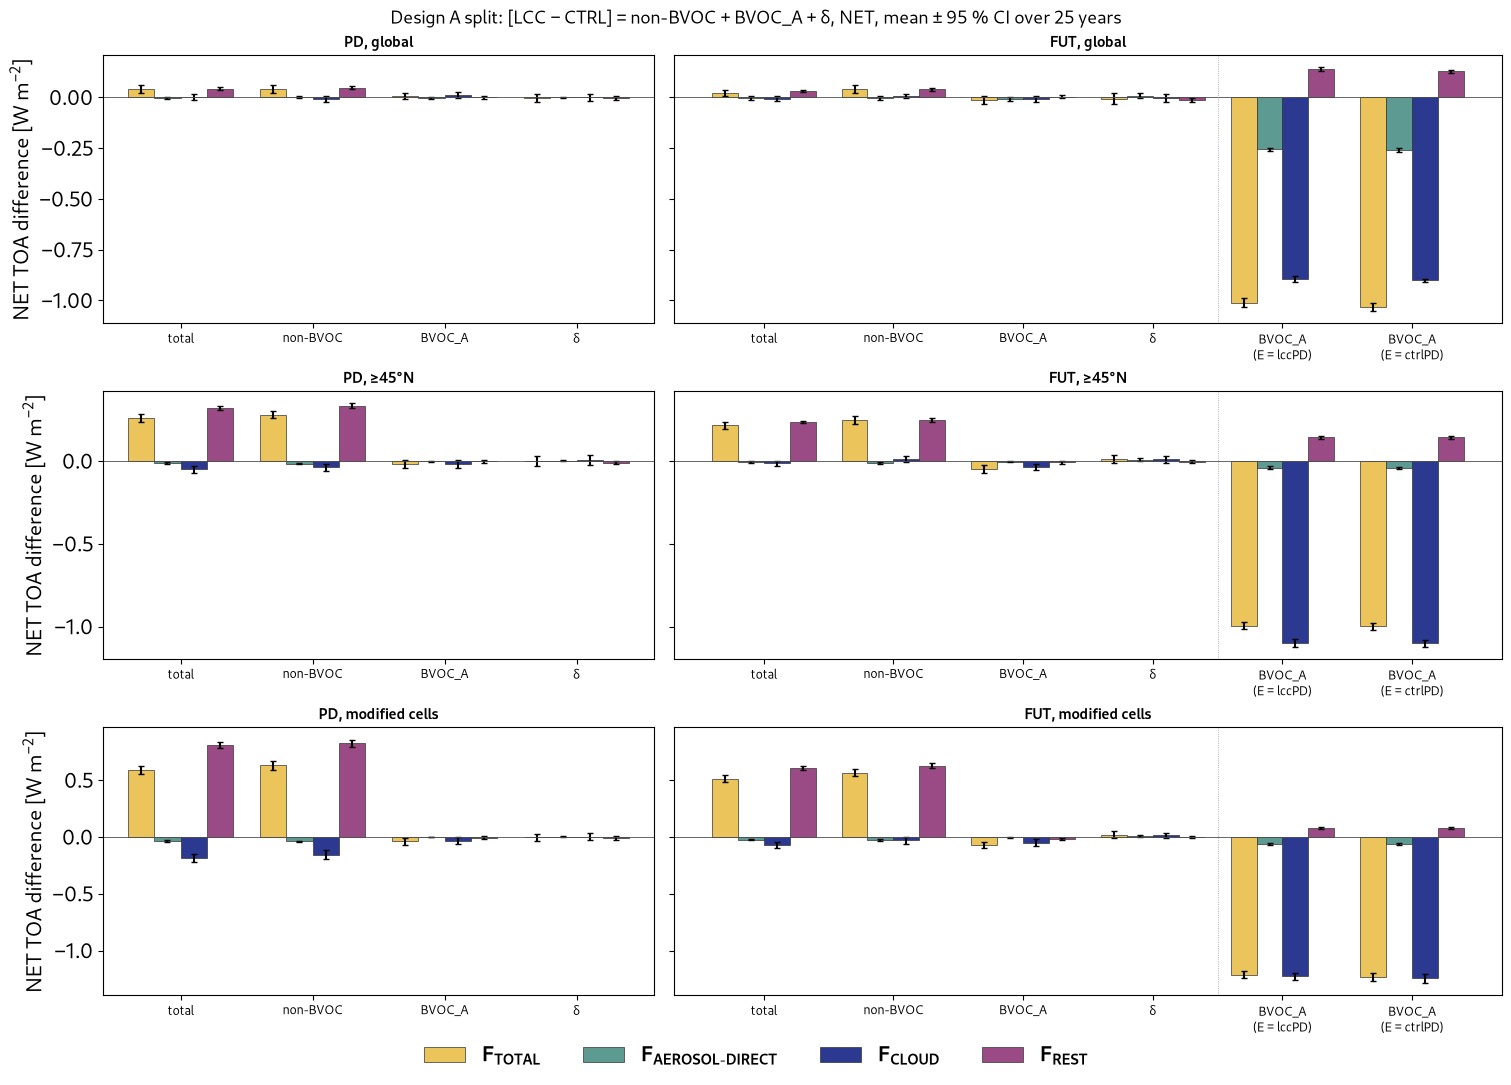

In [4]:
s = rad_s[rad_s.band == "NET"]
fig, axes = plt.subplots(len(REGIONS), 2, figsize=(15, 3.6 * len(REGIONS)), sharey="row", constrained_layout=True,
                         gridspec_kw=dict(width_ratios=[4, 6]))
wbar = 0.2
for i, region in enumerate(REGIONS):
    for j, P in enumerate(("PD", "FUT")):
        ax = axes[i, j]; order = [c for c in ORDER if c in split_terms(P)]; x = np.arange(len(order))
        for k, term in enumerate(fm.GHAN_TERMS):
            sub = s[(s.region == region) & (s.period == P) & (s.term == term)].set_index("contrast").reindex(order)
            name, color = fm.TERM_STYLE[term]
            ax.bar(x + (k - 1.5) * wbar, sub["mean"], wbar, yerr=sub["ci95"], color=color, edgecolor="0.2",
                   linewidth=0.5, capsize=2, label=name if (i, j) == (0, 0) else None)
        ax.axhline(0, color="0.3", lw=0.6)
        if len(order) > 4: ax.axvline(3.5, color="0.6", lw=0.6, ls=":")   # closed split | other E
        ax.set_xticks(x, [c.replace(" (", "\n(") for c in order], fontsize=9)
        ax.set_title(f"{P}, {region}", fontsize=10.5, fontweight="semibold")
        if j == 0: ax.set_ylabel("NET TOA difference [W m$^{-2}$]")
fig.legend(loc="outside lower center", ncol=4, frameon=False)
fig.suptitle(f"Design A split: [LCC − CTRL] = non-BVOC + BVOC_A + δ, NET, "
             f"mean ± 95 % CI over {fm.n_years(START_YEAR, END_YEAR)} years", fontsize=13)
path = FIG / f"radiative_budget_split_NET_{START_YEAR}_{END_YEAR}_designA.png"
fig.savefig(path, dpi=200, bbox_inches="tight"); print("Saved", path)
plt.show(); plt.close(fig)

## 3. Findings
_Filled after the run (numbers from the tables above, with evidence tags)._